# 05 · `simplify.py`: collapsing Allen subtrees

NextBrain/Allen maps are very fine-grained: the thalamus alone has dozens of
nuclei. `simplify(allen, labels, hide_missing=False, compat16bits=False, save=False)`
**merges every descendant of each listed node into that node's ID**.

* `labels` can mix **acronyms** (`"THM"`), **names** (`"thalamus"`),
  **normalised names**, and **IDs** (as `int` or as a string such as `"10390"`).
* `hide_missing=True` sets every voxel that does not fall under a listed node
  to 0. Otherwise those voxels keep their value.
* `compat16bits=True` is needed when the input was produced with
  `to_allen(..., compat16bits=True)`.

In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, ".")          # nb_helpers.py lives next to the notebooks
WORK = Path("_work/05"); WORK.mkdir(parents=True, exist_ok=True)   # scratch outputs of this notebook

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import nb_helpers as H
pd.set_option("display.max_rows", 60, "display.max_colwidth", 70)

In [2]:
from nextbrain_utils import combine_hemis
from nextbrain_utils.simplify import simplify, get_allen2simple_map
from nextbrain_utils.to_allen import to_allen
from nextbrain_utils.lut import allen_lut
from nextbrain_utils.io import load_lut, load_ontology
nxb_lut, ont = load_lut(), load_ontology()

nib.save(H.make_phantom_hemi("L"), WORK / "seg.left.nii.gz")
nib.save(H.make_phantom_hemi("R"), WORK / "seg.right.nii.gz")
combined, sides = combine_hemis(WORK / "seg.left.nii.gz", WORK / "seg.right.nii.gz")
with H.patched_nextbrain_lut():                   # see notebook 04, bug 1
    allen = to_allen(combined, "gyral", save=WORK / "seg.allen.nii.gz")

allen_rows = allen_lut()
names = {r[0]: r[1] for r in allen_rows}
def describe(img):
    d = np.asarray(img.dataobj)
    return pd.DataFrame([(int(v), names.get(int(v), "<not Allen>"), int(c))
                         for v, c in zip(*np.unique(d, return_counts=True)) if v],
                        columns=["id", "name", "voxels"])
describe(allen)

,id,name,voxels
0,10335,head_of_caudate,694
1,10338,putamen,1542
2,10343,external_segment_of_globus_pallidus,334
3,10346,claustrum,294
4,10361,amygdaloid_complex,382
5,10390,thalamus,1421
6,10557,white_matter_of_forebrain,54225
7,10597,anterior_horn_of_lateral_ventricle,798
8,10648,midbrain_(mesencephalon),682
9,10668,white_matter_of_hindbrain,950


## How `get_allen2simple_map` works

1. Allocate a mapping of length **2²⁹** (needed because Allen IDs reach about
   2.7·10⁸): `np.arange` if `hide_missing=False`, `np.zeros` otherwise. As
   `int32`, that is **2 GiB**, allocated on every call (issue 7).
2. Walk the tree from the root. When a node matches one of `labels`, assign
   its ID to the node **and all its descendants**, and **do not go deeper**.
   Otherwise, recurse into its children.

Consequence of step 2: if you list a parent and one of its children, the
**parent wins** and the child is ignored.

In [3]:
_ = get_allen2simple_map(["THM", "Pu"], verbose=True)     # verbose prints each node that matched
print("mapping length:", _.shape[0], " ->", _.nbytes / 2**30, "GiB")
del _

putamen:
thalamus:
mapping length: 536870912  -> 2.0 GiB


In [4]:
README_LABELS = "AMY ATA EXA Ca Pu NAC GP Cla BF THM SubTH HTH HIP".split()
simple = simplify(allen, README_LABELS)
describe(simple)

,id,name,voxels
0,10294,hippocampus_(hippocampal_formation),518
1,10334,caudate_nucleus,694
2,10338,putamen,1542
3,10342,globus_pallidus,334
4,10346,claustrum,294
5,10361,amygdaloid_complex,382
6,10390,thalamus,1421
7,10557,white_matter_of_forebrain,54225
8,10597,anterior_horn_of_lateral_ventricle,798
9,10648,midbrain_(mesencephalon),682


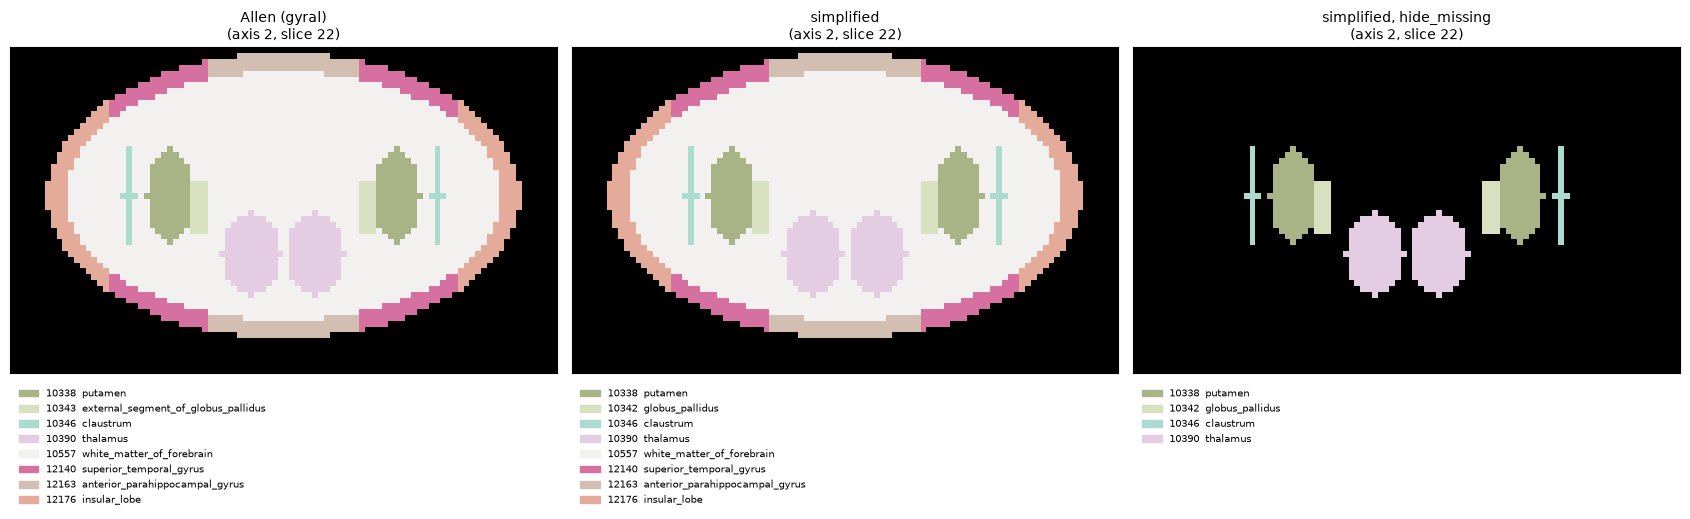

In [6]:
simple_hide = simplify(allen, README_LABELS, hide_missing=True)
H.show_seg([allen, simple, simple_hide], allen_rows, axis=2, index=22,
           titles=["Allen (gyral)", "simplified", "simplified, hide_missing"], figsize=(17, 7))

### Parent vs child: the first match from the top wins

In [6]:
m_child  = get_allen2simple_map(["GPe"])            # only the external pallidum
m_parent = get_allen2simple_map(["GP", "GPe"])      # GP is the parent of GPe -> GPe is ignored
def find(acr, node=ont):
    if node["acronym"] == acr: return node
    for c in node.get("children", []):
        r = find(acr, c)
        if r: return r
gpe = find("GPe")
print("GPe id", gpe["id"], "| ['GPe'] ->", m_child[gpe["id"]], "| ['GP','GPe'] ->", m_parent[gpe["id"]], "(= GP)")
del m_child, m_parent

GPe id 10343 | ['GPe'] -> 10343 | ['GP','GPe'] -> 10342 (= GP)


### Matching rules for `labels`

Strings that look like integers are converted to `int` first, so `"10390"` and
`10390` behave the same. A label that matches nothing is silently ignored.
Check with `verbose=True`.

In [7]:
for spec in [["THM"], ["thalamus"], [10390], ["10390"], ["Thalamus"], ["does-not-exist"]]:
    mp = get_allen2simple_map(spec)
    print(f"{str(spec):20s} changes {int((mp != np.arange(mp.size, dtype=mp.dtype)).sum()):3d} entries")
    del mp

['THM']              changes 115 entries


['thalamus']         changes 115 entries


[10390]              changes 115 entries


['10390']            changes 115 entries


['Thalamus']         changes   0 entries


['does-not-exist']   changes   0 entries


Names are case-sensitive (`"Thalamus"` matches nothing).

## With 16-bit labels

If the map came from `to_allen(..., compat16bits=True)`, pass
`compat16bits=True` here too. The code then remaps the *values* of the mapping
and copies the large-ID rows onto their small-ID positions, so that indices
like 888 (frontal pole) are looked up correctly.

In [8]:
with H.patched_nextbrain_lut():
    allen16 = to_allen(combined, "gyral", compat16bits=True)
simple16 = simplify(allen16, README_LABELS, compat16bits=True)
print("dtype", np.asarray(simple16.dataobj).dtype, "| labels:", np.unique(np.asarray(simple16.dataobj)))

dtype int16 | labels: [    0 10294 10334 10338 10342 10346 10361 10390 10557 10597 10648 10668
 12114 12115 12140 12163 12176 13251]


Note: `simplify` sets the output dtype from the *input* dtype
(`header.set_data_dtype(allen_dat.dtype)`, unlike the other modules). That is
fine here, but worth knowing.

Next: **06 · ASeg / SuperSynth / Laura**.